# Китанин Фёдор РК-1 Вариант 2

## 0. Подготовка

In [5]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Реализация правил обучения

### Правило Хебба

В правиле Хебба веса и смещение обновляются по следующим формулам:

$w_i^{(n+1)} = w_i^{(n)} + \eta x_i \hat y$

$b^{(n+1)} = b^{(n)} + \eta \hat y$,

где $x_i$ - значение i-го входа, $\eta$ - learning rate, $n$ - номер итерации, $\hat y = w^T x + b$ - предсказание модели.

In [6]:
def step_hebb(x, w, b, eta):
    y_pred = w @ x + b
    w_new = w + eta * x * y_pred
    b_new = b + eta * y_pred
    return w_new, b_new

### Правило Хебба с нормировкой

После обновления по правилу Хебба нормируем веса и смещение

s = $\sqrt{w_1^2 + w_2^2 + \ldots + w_k^2 + b^2}$

$w_i$ = $w_i$ / s

b = b / s

Если s = 0 - ничего не меняем

In [7]:
def step_hebb_norm(x, w, b, eta):
    w_new, b_new = step_hebb(x, w, b, eta)
    s = np.sqrt(w_new @ w_new + b_new ** 2)
    if s != 0:
        w_new = w_new / s
        b_new = b_new / s
    return w_new, b_new

### Дельта-правило Уидро–Хоффа

В правиле Уидро–Хоффа веса и смещение обновляются по следующим формулам:

$w_i^{(n+1)} = w_i^{(n)} + \eta x_i (y - \hat y)$

$b^{(n+1)} = b^{(n)} + \eta (y - \hat y)$ ,

где $x_i$ - значение i-го входа, $\eta$ - learning rate, n - номер итерации, y - правильный ответ, $\hat y$ - предсказание.

In [8]:
def step_widrow_hoff(x, y, w, b, eta):
    y_pred = w @ x + b
    error = y - y_pred
    w_new = w + eta * x * error
    b_new = b + eta * error
    return w_new, b_new

## 2. Аппроксимация линейной функции на зашумленных данных

### Подготовка данных

Пусть y = 2 * $x_1$ - 3 * $x_2$ + 1

Добавим епсилон, который является шумом и его значение распределено нормально

$y_{noise}$ = y + $\varepsilon$

Возьмем 3 уровня зашумленности со стандартным отклонением 0.25, 0.75 и 1.25 соответственно

Меняем только стандартное отклонение (силу шума)

In [9]:
rng = np.random.default_rng(42)

X = rng.uniform(-1, 1, (200, 2))
X_test = rng.uniform(-1, 1, (200, 2))

y_clean = 2 * X[:, 0] - 3 * X[:, 1] + 1
y_test_clean = 2 * X_test[:, 0] - 3 * X_test[:, 1] + 1

noise = rng.normal(0, 1, 200)
noise_test = rng.normal(0, 1, 200)
sigmas = [0.25, 0.75, 1.25]

Y = []
Y_test = []

for sigma in sigmas:
    Y.append(y_clean + sigma * noise)
    Y_test.append(y_test_clean + sigma * noise_test)

Y = np.array(Y)
Y_test = np.array(Y_test)

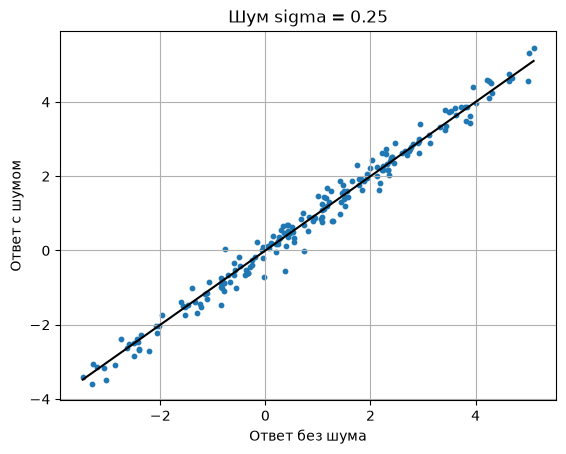

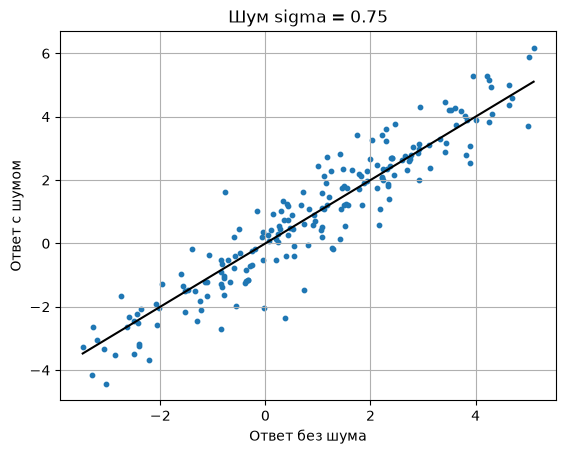

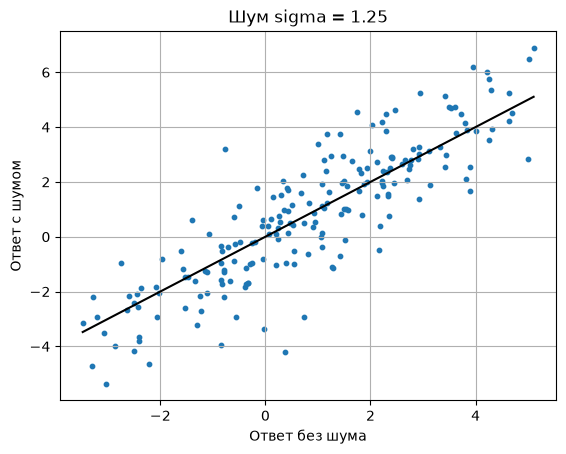

In [10]:
for i in range(3):
    plt.figure()
    plt.scatter(y_clean, Y[i], s=10)
    plt.plot([y_clean.min(), y_clean.max()],
             [y_clean.min(), y_clean.max()], color="black")
    plt.title("Шум sigma = " + str(sigmas[i]))
    plt.xlabel("Ответ без шума")
    plt.ylabel("Ответ с шумом")
    plt.grid()
    plt.show()

### Обучение

#### Хебб без нормировки

In [11]:
mu = 0.01
epochs = 50

train_hebb_raw = []
test_hebb_raw = []
pred_hebb_raw = []

for i in range(3):
    train_runs = []
    test_runs = []
    predictions = []

    for seed in range(10):
        rng = np.random.default_rng(seed)
        w = rng.normal(0, 0.5, 2)
        b = rng.normal(0, 0.5)

        train_loss = [np.mean((Y[i] - (X @ w + b)) ** 2)]
        test_loss = [np.mean((Y_test[i] - (X_test @ w + b)) ** 2)]

        for epoch in range(epochs):
            for j in range(len(X)):
                w, b = step_hebb(X[j], w, b, mu)

            train_loss.append(np.mean((Y[i] - (X @ w + b)) ** 2))
            test_loss.append(np.mean((Y_test[i] - (X_test @ w + b)) ** 2))

        train_runs.append(train_loss)
        test_runs.append(test_loss)
        predictions.append(X_test @ w + b)

    train_hebb_raw.append(train_runs)
    test_hebb_raw.append(test_runs)
    pred_hebb_raw.append(predictions)

train_hebb_raw = np.array(train_hebb_raw)
test_hebb_raw = np.array(test_hebb_raw)
pred_hebb_raw = np.array(pred_hebb_raw)

#### Хебб с нормировкой

In [12]:
mu = 0.01
epochs = 50

train_hebb = []
test_hebb = []
pred_hebb = []

for i in range(3):
    train_runs = []
    test_runs = []
    predictions = []

    for seed in range(10):
        rng = np.random.default_rng(seed)
        w = rng.normal(0, 0.5, 2)
        b = rng.normal(0, 0.5)

        train_loss = [np.mean((Y[i] - (X @ w + b)) ** 2)]
        test_loss = [np.mean((Y_test[i] - (X_test @ w + b)) ** 2)]

        for epoch in range(epochs):
            for j in range(len(X)):
                w, b = step_hebb_norm(X[j], w, b, mu)

            train_loss.append(np.mean((Y[i] - (X @ w + b)) ** 2))
            test_loss.append(np.mean((Y_test[i] - (X_test @ w + b)) ** 2))

        train_runs.append(train_loss)
        test_runs.append(test_loss)
        predictions.append(X_test @ w + b)

    train_hebb.append(train_runs)
    test_hebb.append(test_runs)
    pred_hebb.append(predictions)

train_hebb = np.array(train_hebb)
test_hebb = np.array(test_hebb)
pred_hebb = np.array(pred_hebb)

#### Уидро-Хофф

In [13]:
train_delta = []
test_delta = []
pred_delta = []

for i in range(3):
    train_runs = []
    test_runs = []
    predictions = []

    for seed in range(10):
        rng = np.random.default_rng(seed)
        w = rng.normal(0, 0.5, 2)
        b = rng.normal(0, 0.5)

        train_loss = [np.mean((Y[i] - (X @ w + b)) ** 2)]
        test_loss = [np.mean((Y_test[i] - (X_test @ w + b)) ** 2)]

        for epoch in range(epochs):
            for j in range(len(X)):
                w, b = step_widrow_hoff(X[j], Y[i, j], w, b, mu)

            train_loss.append(np.mean((Y[i] - (X @ w + b)) ** 2))
            test_loss.append(np.mean((Y_test[i] - (X_test @ w + b)) ** 2))

        train_runs.append(train_loss)
        test_runs.append(test_loss)
        predictions.append(X_test @ w + b)

    train_delta.append(train_runs)
    test_delta.append(test_runs)
    pred_delta.append(predictions)

train_delta = np.array(train_delta)
test_delta = np.array(test_delta)
pred_delta = np.array(pred_delta)

### Кривые MSE

Тусклые линии - отдельные сиды, толстые - среднее по всем сидам. Хебба без нормировки покажу отдельно из-за большой MSE. 

#### Хебб без нормировки на обучении и тесте

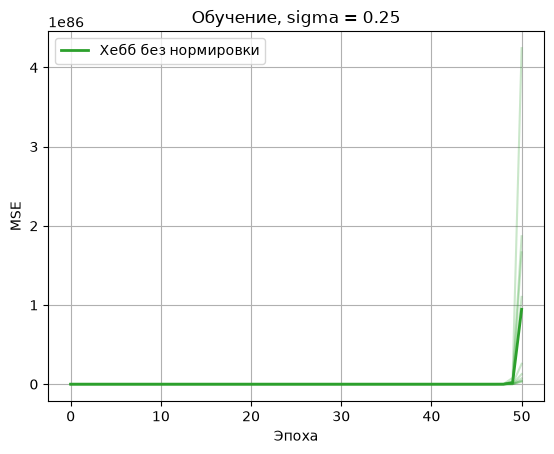

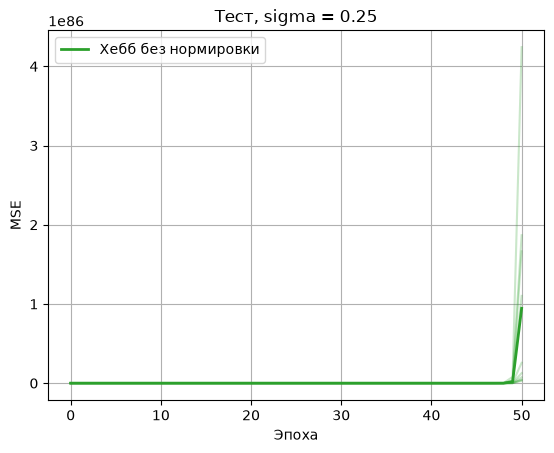

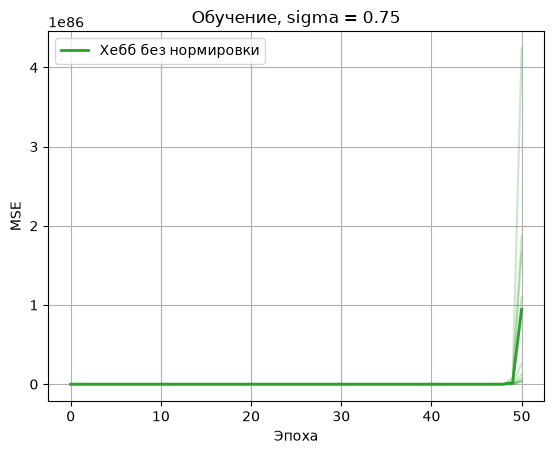

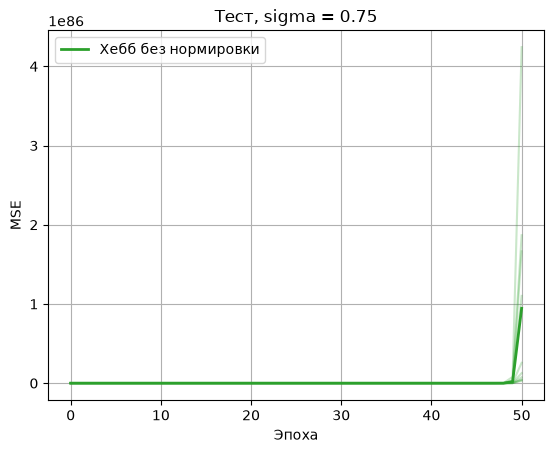

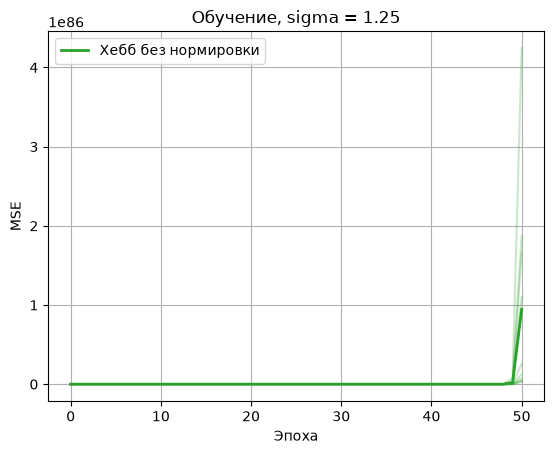

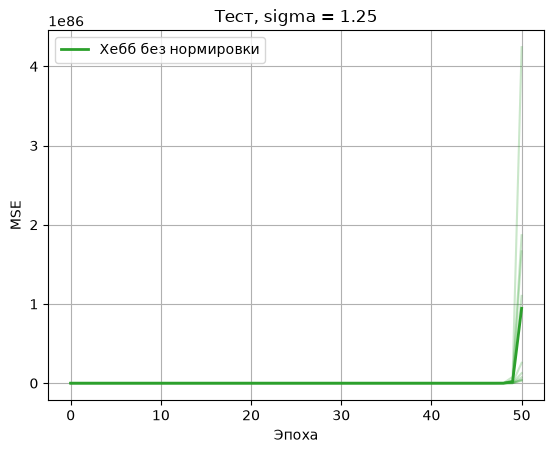

In [14]:
for i in range(3):
    plt.figure()
    for seed in range(10):
        plt.plot(train_hebb_raw[i, seed], color="C2", alpha=0.25)
    plt.plot(train_hebb_raw[i].mean(axis=0), color="C2", linewidth=2, label="Хебб без нормировки")
    plt.title("Обучение, sigma = " + str(sigmas[i]))
    plt.xlabel("Эпоха")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure()
    for seed in range(10):
        plt.plot(test_hebb_raw[i, seed], color="C2", alpha=0.25)
    plt.plot(test_hebb_raw[i].mean(axis=0), color="C2", linewidth=2, label="Хебб без нормировки")
    plt.title("Тест, sigma = " + str(sigmas[i]))
    plt.xlabel("Эпоха")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid()
    plt.show()

Без нормировки MSE быстро растет на обучении и тесте при всех сидах.

#### Хебб с нормировкой и Уидро-Хофф 

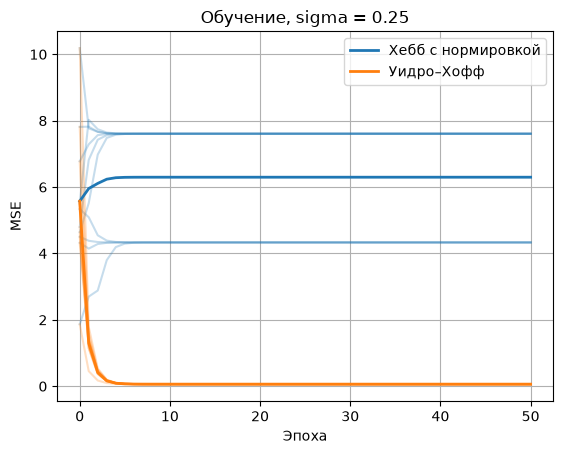

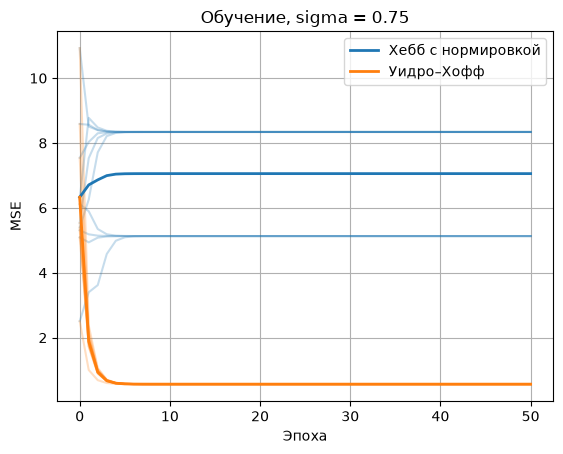

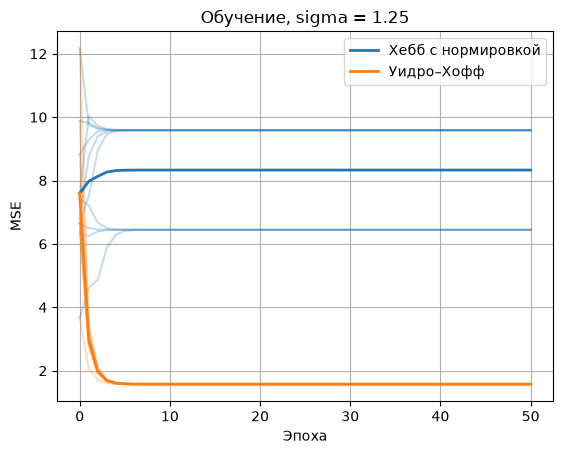

In [15]:
for i in range(3):
    plt.figure()

    for seed in range(10):
        plt.plot(train_hebb[i, seed], color="C0", alpha=0.25)
        plt.plot(train_delta[i, seed], color="C1", alpha=0.25)

    plt.plot(train_hebb[i].mean(axis=0), color="C0", linewidth=2, label="Хебб с нормировкой")
    plt.plot(train_delta[i].mean(axis=0), color="C1", linewidth=2, label="Уидро–Хофф")
    plt.title("Обучение, sigma = " + str(sigmas[i]))
    plt.xlabel("Эпоха")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid()
    plt.show()

Уидро-Хофф уменьшает MSE. У Хебба с нормировкой ошибка остается большой и для части сида растет.

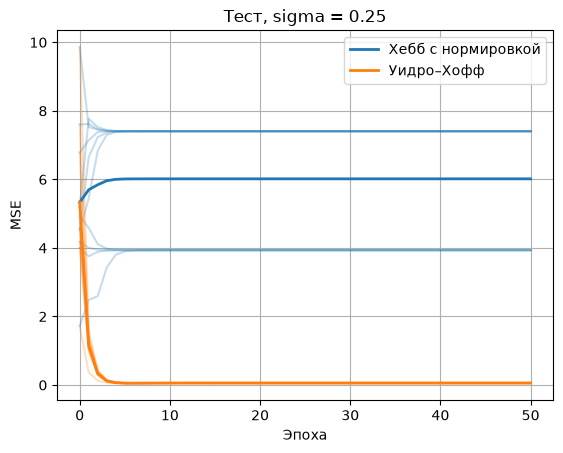

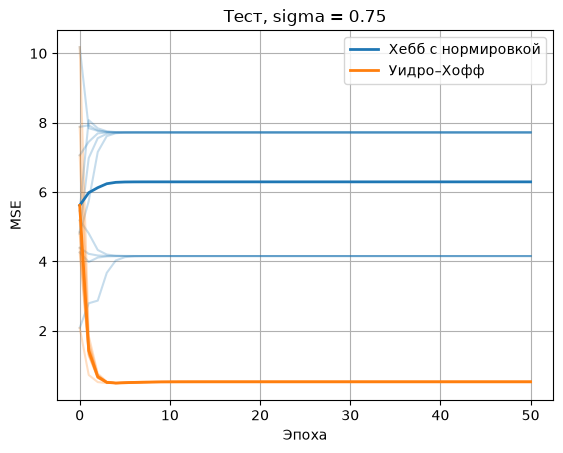

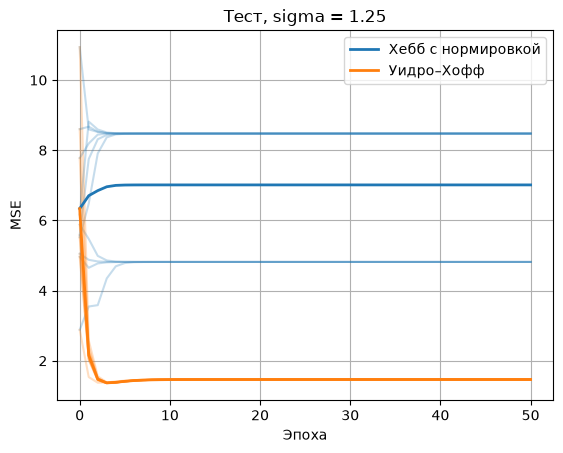

In [16]:
for i in range(3):
    plt.figure()

    for seed in range(10):
        plt.plot(test_hebb[i, seed], color="C0", alpha=0.25)
        plt.plot(test_delta[i, seed], color="C1", alpha=0.25)

    plt.plot(test_hebb[i].mean(axis=0), color="C0", linewidth=2, label="Хебб с нормировкой")
    plt.plot(test_delta[i].mean(axis=0), color="C1", linewidth=2, label="Уидро–Хофф")
    plt.title("Тест, sigma = " + str(sigmas[i]))
    plt.xlabel("Эпоха")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid()
    plt.show()

На проверке Уидро–Хофф тоже лучше. Больше шум => больше итоговая MSE.

### Статистики

Среднее и стандартное отклонение MSE по 10 сидов на одних данных.

In [17]:
for i in range(3):
    print("Шум", sigmas[i])
    print("Хебб без нормировки")
    print("MSE на обучении:", train_hebb_raw[i, :, -1].mean(),
          "стандартное отклонение:", train_hebb_raw[i, :, -1].std())
    print("MSE на тесте:", test_hebb_raw[i, :, -1].mean(),
          "стандартное отклонение:", test_hebb_raw[i, :, -1].std())
    print("Хебб с нормировкой")
    print("MSE на обучении:", train_hebb[i, :, -1].mean(),
          "стандартное отклонение:", train_hebb[i, :, -1].std())
    print("MSE на тесте:", test_hebb[i, :, -1].mean(),
          "стандартное отклонение:", test_hebb[i, :, -1].std())
    print("Уидро–Хофф")
    print("MSE на обучении:", train_delta[i, :, -1].mean(),
          "стандартное отклонение:", train_delta[i, :, -1].std())
    print("MSE на тесте:", test_delta[i, :, -1].mean(),
          "стандартное отклонение:", test_delta[i, :, -1].std())
    print()

Шум 0.25
Хебб без нормировки
MSE на обучении: 9.450233392290832e+85 стандартное отклонение: 1.2903701184351652e+86
MSE на тесте: 9.446205538008269e+85 стандартное отклонение: 1.289820140186811e+86
Хебб с нормировкой
MSE на обучении: 6.297436498529752 стандартное отклонение: 1.6046180024782932
MSE на тесте: 6.0162680602649825 стандартное отклонение: 1.7003802433003878
Уидро–Хофф
MSE на обучении: 0.06303161433971374 стандартное отклонение: 2.443436683771534e-17
MSE на тесте: 0.05864170713196715 стандартное отклонение: 1.254004232216558e-15

Шум 0.75
Хебб без нормировки
MSE на обучении: 9.450233392290832e+85 стандартное отклонение: 1.2903701184351652e+86
MSE на тесте: 9.446205538008269e+85 стандартное отклонение: 1.289820140186811e+86
Хебб с нормировкой
MSE на обучении: 7.056212932709464 стандартное отклонение: 1.5718404988483834
MSE на тесте: 6.294303146696369 стандартное отклонение: 1.7464594311048727
Уидро–Хофф
MSE на обучении: 0.5672845290574247 стандартное отклонение: 9.2887922524162

### Результат аппроксимации

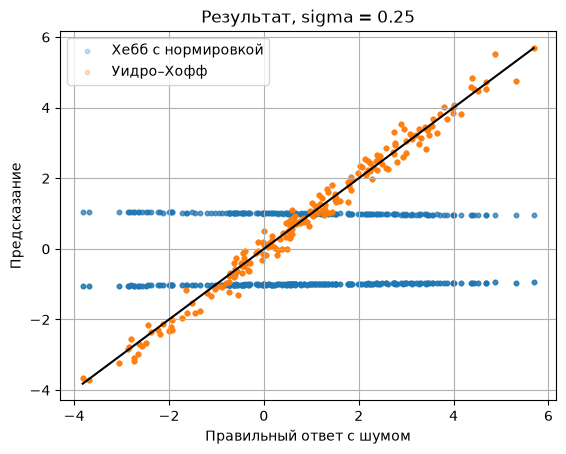

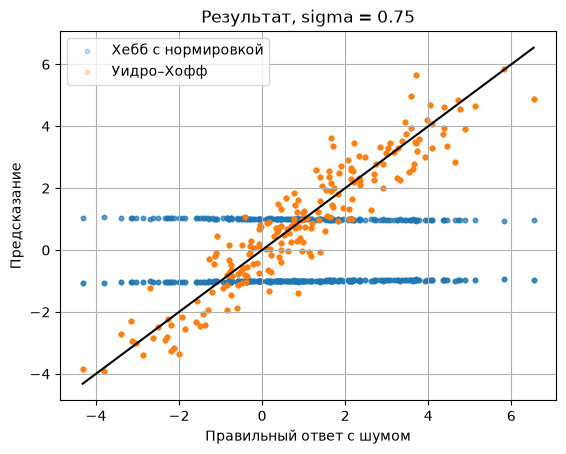

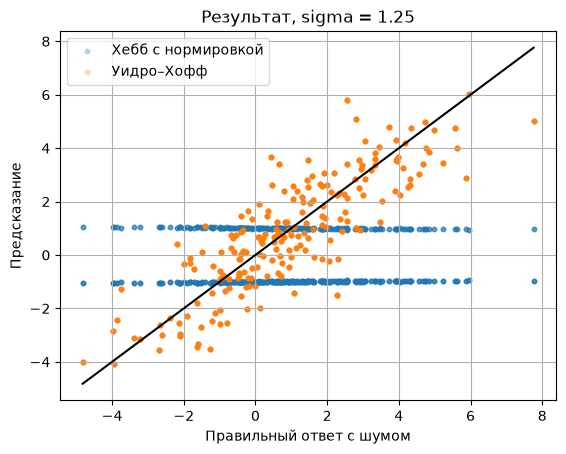

In [18]:
for i in range(3):
    plt.figure()

    answers = np.tile(Y_test[i], len(pred_hebb[i]))

    plt.scatter(answers, pred_hebb[i].flatten(), s=10, alpha=0.25, label="Хебб с нормировкой")
    plt.scatter(answers, pred_delta[i].flatten(), s=10, alpha=0.25, label="Уидро–Хофф")

    limits = [Y_test[i].min(), Y_test[i].max()]
    plt.plot(limits, limits, color="black")

    plt.title("Результат, sigma = " + str(sigmas[i]))
    plt.xlabel("Правильный ответ с шумом")
    plt.ylabel("Предсказание")
    plt.legend()
    plt.grid()
    plt.show()

Уидро–Хофф восстанавливает функцию. У Хебба с нормировкой ответы либо около 1, либо около -1

## 3. Аналитическое исследование Хебба и Уидро–Хоффа

### Ручные вычисления на малом примере

Пусть $y = 2x_1 - 3x_2 + 1$. Возьмём четыре объекта:

$(1, 0)$; $y = 3$

$(-1, 0)$; $y = -1$

$(0, 1)$; $y = -2$

$(0, -1)$; $y = 4$.

Средние значения признаков равны нулю

$M[x_1] = (1 - 1 + 0 + 0)/4 = 0$

$M[x_2] = (0 + 0 + 1 - 1)/4 = 0$.

Пусть $w = (1, 1)$, $b = 1$, $\eta = 0.2$. Для каждого правила начинаем с этих же параметров.

Начальное предсказания для четырёх объектов  $\hat y = (2, 0, 2, 0)$.

Начальная ошибка:

$MSE = ((3 - 2)^2 + (-1 - 0)^2 + (-2 - 2)^2 + (4 - 0)^2)/4 = 8.5$.

Посчитаем ошибку после каждого шага. Один шаг означает среднюю поправку по четырём объектам при одних и тех же текущих параметрах.

#### Хебб без нормировки

***1-я итерация***

$w_1 = 1 + 0.2 \cdot (2 + 0 + 0 + 0)/4 = 1.1$

$w_2 = 1 + 0.2 \cdot (0 + 0 + 2 + 0)/4 = 1.1$

$b = 1 + 0.2 \cdot (2 + 0 + 2 + 0)/4 = 1.2$

$\hat y_1 = 1.1 \cdot 1 + 1.1 \cdot 0 + 1.2 = 2.3$

$\hat y_2 = 1.1 \cdot (-1) + 1.1 \cdot 0 + 1.2 = 0.1$

$\hat y_3 = 1.1 \cdot 0 + 1.1 \cdot 1 + 1.2 = 2.3$

$\hat y_4 = 1.1 \cdot 0 + 1.1 \cdot (-1) + 1.2 = 0.1$

$MSE = \big((3 - 2.3)^2 + (-1 - 0.1)^2 + (-2 - 2.3)^2 + (4 - 0.1)^2\big)/4 = 8.85$

***2-я итерация***

$w_1 = 1.1 + 0.2 \cdot (2.3 - 0.1 + 0 + 0)/4 = 1.21$

$w_2 = 1.1 + 0.2 \cdot (0 + 0 + 2.3 - 0.1)/4 = 1.21$

$b = 1.2 + 0.2 \cdot (2.3 + 0.1 + 2.3 + 0.1)/4 = 1.44$

$\hat y_1 = 1.21 \cdot 1 + 1.21 \cdot 0 + 1.44 = 2.65$

$\hat y_2 = 1.21 \cdot (-1) + 1.21 \cdot 0 + 1.44 = 0.23$

$\hat y_3 = 1.21 \cdot 0 + 1.21 \cdot 1 + 1.44 = 2.65$

$\hat y_4 = 1.21 \cdot 0 + 1.21 \cdot (-1) + 1.44 = 0.23$

$MSE = \big((3 - 2.65)^2 + (-1 - 0.23)^2 + (-2 - 2.65)^2 + (4 - 0.23)^2\big)/4 = 9.3677$

Ошибка только растет!!!

#### Хебб с нормировкой

***1-я итерация***

До нормировки

$w_1 = w_2 = 1 + 0.2 \cdot 2/4 = 1.1$

$b = 1 + 0.2 \cdot (2 + 0 + 2 + 0)/4 = 1.2$

Нормируем параметры

$s = \sqrt{1.1^2 + 1.1^2 + 1.2^2} \approx 1.964688$

$w_1 = w_2 = 1.1/s \approx 0.559885$

$b = 1.2/s \approx 0.610784$

$\hat y_1 = 0.559885 \cdot 1 + 0.559885 \cdot 0 + 0.610784 = 1.170669$

$\hat y_2 = 0.559885 \cdot (-1) + 0.559885 \cdot 0 + 0.610784 = 0.050899$

$\hat y_3 = 0.559885 \cdot 0 + 0.559885 \cdot 1 + 0.610784 = 1.170669$

$\hat y_4 = 0.559885 \cdot 0 + 0.559885 \cdot (-1) + 0.610784 = 0.050899$

$MSE = \big((3 - 1.170669)^2 + (-1 - 0.050899)^2 + (-2 - 1.170669)^2 + (4 - 0.050899)^2\big)/4 \approx 7.524846$

***2-я итерация***

До нормировки

$w_1 = w_2 \approx 0.559885 + 0.2 \cdot (1.170669 - 0.050899)/4 \approx 0.615874$

$b \approx 0.610784 + 0.2 \cdot (1.170669 + 0.050899 + 1.170669 + 0.050899)/4 \approx 0.732941$

Нормируем параметры

$s = \sqrt{0.615874^2 + 0.615874^2 + 0.732941^2} \approx 1.138333$

$w_1 = w_2 \approx 0.615874/s \approx 0.541031$

$b \approx 0.732941/s \approx 0.643872$

$\hat y_1 = 0.541031 \cdot 1 + 0.541031 \cdot 0 + 0.643872 = 1.184903$

$\hat y_2 = 0.541031 \cdot (-1) + 0.541031 \cdot 0 + 0.643872 = 0.102841$

$\hat y_3 = 0.541031 \cdot 0 + 0.541031 \cdot 1 + 0.643872 = 1.184903$

$\hat y_4 = 0.541031 \cdot 0 + 0.541031 \cdot (-1) + 0.643872 = 0.102841$

$MSE = \big((3 - 1.184903)^2 + (-1 - 0.102841)^2 + (-2 - 1.184903)^2 + (4 - 0.102841)^2\big)/4 \approx 7.460573$

Ошибка медленно падает

#### Уидро–Хофф

***1-я итерация***

Начальные параметры $w = (1, 1)$, $b = 1$

$y - \hat y = (1, -1, -4, 4)$

$w_1 = 1 + 0.2 \cdot (1 + 1 + 0 + 0)/4 = 1.1$

$w_2 = 1 + 0.2 \cdot (0 + 0 - 4 - 4)/4 = 0.6$

$b = 1 + 0.2 \cdot (1 - 1 - 4 + 4)/4 = 1$

$\hat y_1 = 1.1 \cdot 1 + 0.6 \cdot 0 + 1 = 2.1$

$\hat y_2 = 1.1 \cdot (-1) + 0.6 \cdot 0 + 1 = -0.1$

$\hat y_3 = 1.1 \cdot 0 + 0.6 \cdot 1 + 1 = 1.6$

$\hat y_4 = 1.1 \cdot 0 + 0.6 \cdot (-1) + 1 = 0.4$

$MSE = \big((3 - 2.1)^2 + (-1 + 0.1)^2 + (-2 - 1.6)^2 + (4 - 0.4)^2\big)/4 = 6.885$

***2-я итерация***

$y - \hat y = (0.9, -0.9, -3.6, 3.6)$

$w_1 = 1.1 + 0.2 \cdot (0.9 + 0.9 + 0 + 0)/4 = 1.19$

$w_2 = 0.6 + 0.2 \cdot (0 + 0 - 3.6 - 3.6)/4 = 0.24$

$b = 1 + 0.2 \cdot (0.9 - 0.9 - 3.6 + 3.6)/4 = 1$

$\hat y_1 = 1.19 \cdot 1 + 0.24 \cdot 0 + 1 = 2.19$

$\hat y_2 = 1.19 \cdot (-1) + 0.24 \cdot 0 + 1 = -0.19$

$\hat y_3 = 1.19 \cdot 0 + 0.24 \cdot 1 + 1 = 1.24$

$\hat y_4 = 1.19 \cdot 0 + 0.24 \cdot (-1) + 1 = 0.76$

$MSE = \big((3 - 2.19)^2 + (-1 + 0.19)^2 + (-2 - 1.24)^2 + (4 - 0.76)^2\big)/4 = 5.57685$

Ошибка падает сильнее

Пока можем сделать выводы, что для правила Хебба нужна нормировка для схождения, без нее ошибка "взрывается". Пока для чего нужно нулевое среднее по рпизнакам непонятно.

### Общее доказательство

### Правило Хебба при нулевом среднем входов

Пусть входов m, среднее каждого входа равно нулю и $\eta > 0$.

$M[x_i] = 0$

$\hat y = w_1x_1 + \ldots + w_mx_m + b$.

Рассматриваем усредненное обновление при фиксированных текущих параметрах.

$M[\Delta w_i] = \eta M[x_i\hat y] = \eta(w_1M[x_ix_1] + \ldots + w_mM[x_ix_m])$


Слагаемое с b исчезает, поскольку $M[x_i] = 0$.

Обозначим $C = M[xx^T]$. Тогда для всех весов сразу

$w^{(n+1)} = w^{(n)} + \eta Cw^{(n)}$

$b^{(n+1)} = (1 + \eta)b^{(n)}$.

### Без нормировки

Смещение после n шагов равно

$b^{(n)} = (1 + \eta)^n b^{(0)}$.

Поэтому при $b^{(0)} \ne 0$ оно растет по модулю без ограничения.

Для весов раскроем квадрат длины после обновления

$\|w^{(n+1)}\|^2 = \|w^{(n)}\|^2 + 2\eta M[((w^{(n)})^Tx)^2] + \eta^2\|Cw^{(n)}\|^2$.

Все добавленные слагаемые неотрицательны. Если данные имеют ненулевой разброс при любом ненулевом сочетании входов, существует число d > 0, для которого

$M[(w^Tx)^2] \geq d\|w\|^2$.

Следовательно,

$\|w^{(n+1)}\|^2 \geq (1 + 2\eta d)\|w^{(n)}\|^2$

$\|w^{(n)}\|^2 \geq (1 + 2\eta d)^n\|w^{(0)}\|^2$.

При ненулевых начальных весах правая часть стремится к бесконечности. Это и объясняет взрыв весов.


### С нормировкой

После обновления делим все параметры на их общую длину

$s = \sqrt{w_1^2 + \ldots + w_m^2 + b^2}$

$w_i = w_i/s$

$b = b/s$.

При $s \ne 0$ получаем

$w_1^2 + \ldots + w_m^2 + b^2 = 1$.

Поэтому бесконечный рост длины прекращается.

### К чему сходится правило Хебба при нулевом среднем входов?

Рассмотрим обновление весов $w^{(n+1)} = w^{(n)} + \eta Cw^{(n)}$.

Пусть $e_1,\ldots,e_m$ являются единичными собственными векторами матрицы $C$:

$Ce_j = \lambda_j e_j$,

$\lambda_1 > \lambda_2 \geq \ldots \geq \lambda_m \geq 0$.

Число $\lambda_j$ показывает разброс входных данных вдоль $e_j$, поскольку $M[(e_j^Tx)^2] = e_j^TCe_j = \lambda_j$.

Представим начальные веса в виде $w^{(0)} = a_1e_1 + \ldots + a_me_m$.

При каждом обновлении составляющая вдоль $e_j$ умножается на $1+\eta\lambda_j$. Поэтому $w^{(n)} = \sum_{j=1}^{m}a_j(1+\eta\lambda_j)^ne_j$.

При $a_1 \ne 0$ отношение любой другой составляющей к первой стремится к нулю:

$\dfrac{a_j(1+\eta\lambda_j)^n}{a_1(1+\eta\lambda_1)^n} = \dfrac{a_j}{a_1}\left(\dfrac{1+\eta\lambda_j}{1+\eta\lambda_1}\right)^n \to 0,\quad j>1$.

Следовательно, первая составляющая постепенно преобладает:

$\dfrac{w^{(n)}}{\|w^{(n)}\|} \to \pm e_1$.

Таким образом, направление приближается к первой главной компоненте, вдоль которой разброс данных наибольший. Знак зависит от начальных весов.

Вывод предполагает, что $\lambda_1>\lambda_2$ и $a_1\ne0$.

При совместной нормировке весов и смещения нужно также учитывать

$b^{(n)} = (1+\eta)^n b^{(0)}$.

При $\lambda_1>1$ преобладает первая составляющая весов. При $\lambda_1<1$ и $b^{(0)}\ne0$ преобладает смещение. При $\lambda_1=1$ их соотношение зависит от начальных параметров.

### Сравнение с минимумом MSE у Уидро–Хоффа

Правило Уидро–Хоффа использует ошибку между правильным ответом и предсказанием

$w_i^{(n+1)} = w_i^{(n)} + \eta x_i(y - \hat y)$

$b^{(n+1)} = b^{(n)} + \eta(y - \hat y)$.

При нулевом среднем входов средние поправки равны

$M[\Delta w] = \eta(M[xy] - Cw)$

$M[\Delta b] = \eta(M[y] - b)$.

В точке минимума MSE эти поправки равны нулю

$Cw = M[xy]$

$b = M[y]$.

Если C обратима, получаем

$w_{min} = C^{-1}M[xy]$

$b_{min} = M[y]$.

Пусть данные получены из линейной функции с шумом $y = a_1x_1 + \ldots + a_mx_m + c + \varepsilon$, где шум независим от входов, $M[\varepsilon] = 0$ и $M[\varepsilon^2] = \sigma^2$.

Тогда

$MSE = M[((a - w)^Tx)^2] + (c - b)^2 + \sigma^2$.

Первые два слагаемых неотрицательны и обращаются в ноль при $w_{min} = a$, $b_{min} = c$.

Поэтому минимальная ожидаемая ошибка равна $MSE_{min} = \sigma^2$.

Уидро–Хофф при достаточно малом шаге в усредненном обновлении сходится к минимуму MSE. При последовательном обучении с постоянным шагом и шумом возможны колебания около минимума.

Без нормировки веса в правиле Хебба обычно растут неограниченно. Нормировка ограничивает их длину, а обучение выделяет направления, вдоль которых данные имеют больший разброс. Правильные ответы y при этом не используются, поэтому правило Хебба не обязательно приводит к минимуму MSE.

## 4. Масштабирование входных признаков

Берем данные пункта 2 со стандартным отклонением 0.25. Умножаем оба входа на 1, 10 и 100, ответы y не меняем.


In [19]:
scales = [1, 10, 100]
mu_scale = 0.005
steps = 10000
y_scale = Y[0]
y_scale_test = Y_test[0]

### Хебб без нормировки

In [20]:
loss_hebb_scale = []

for scale in scales:
    X_scale = X * scale
    X_scale_test = X_test * scale
    rng = np.random.default_rng(0)
    w = rng.normal(0, 0.5, 2)
    b = rng.normal(0, 0.5)
    loss = [np.mean((y_scale - (X_scale @ w + b)) ** 2)]

    for i in range(steps):
        j = i % len(X_scale)
        w, b = step_hebb(X_scale[j], w, b, mu_scale)
        loss.append(np.mean((y_scale - (X_scale @ w + b)) ** 2))
        if loss[-1] > 1e12:
            break

    loss_hebb_scale.append(np.array(loss))
    print("Масштаб", scale, "обновлений", len(loss) - 1)
    print("Последняя MSE на обучении:", loss[-1])
    print("MSE на проверке:", np.mean((y_scale_test - (X_scale_test @ w + b)) ** 2))
    print("Длина весов и смещения:", np.sqrt(w @ w + b ** 2))
    if loss[-1] > 1e12:
        print("Остановка: MSE превысила 1e12")
    print()

Масштаб 1 обновлений 3000
Последняя MSE на обучении: 1006701584249.3539
MSE на проверке: 1006418654927.677
Длина весов и смещения: 1002216.353527772
Остановка: MSE превысила 1e12

Масштаб 10 обновлений 109
Последняя MSE на обучении: 1489566141107.2312
MSE на проверке: 1651775909557.5344
Длина весов и смещения: 210342.77866080627
Остановка: MSE превысила 1e12

Масштаб 100 обновлений 5
Последняя MSE на обучении: 1173013386134.1113
MSE на проверке: 1430149342101.7961
Длина весов и смещения: 18809.94075328307
Остановка: MSE превысила 1e12



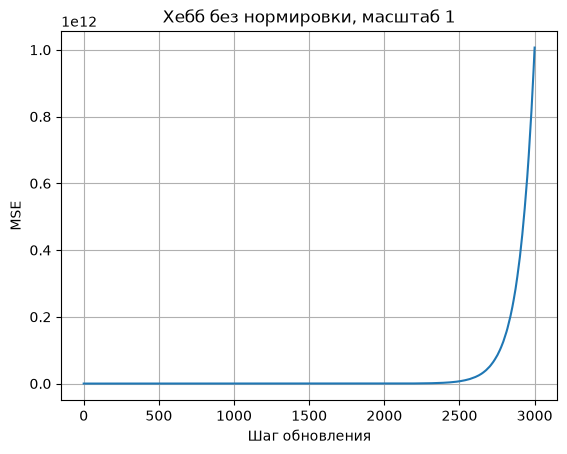

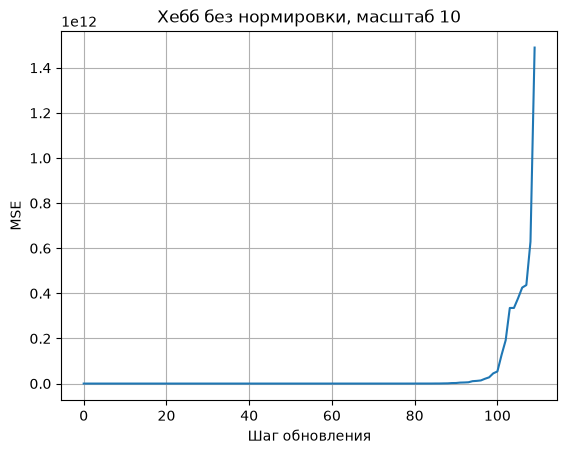

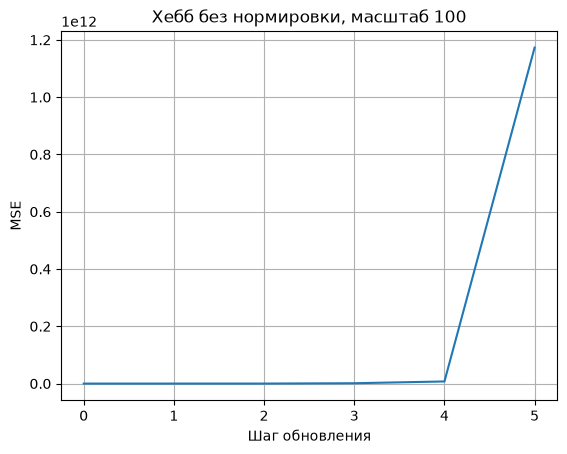

In [21]:
for i in range(3):
    plt.figure()
    plt.plot(loss_hebb_scale[i])
    plt.title("Хебб без нормировки, масштаб " + str(scales[i]))
    plt.xlabel("Шаг обновления")
    plt.ylabel("MSE")
    plt.grid()
    plt.show()

Порог MSE превышен после 3000, 109 и 5 обновлений => при увеличении масштаба рост весов и ошибки происходит быстрее.

### Хебб с нормировкой

In [22]:
loss_norm_scale = []

for scale in scales:
    X_scale = X * scale
    X_scale_test = X_test * scale
    rng = np.random.default_rng(0)
    w = rng.normal(0, 0.5, 2)
    b = rng.normal(0, 0.5)
    loss = [np.mean((y_scale - (X_scale @ w + b)) ** 2)]

    for i in range(steps):
        j = i % len(X_scale)
        w, b = step_hebb_norm(X_scale[j], w, b, mu_scale)
        loss.append(np.mean((y_scale - (X_scale @ w + b)) ** 2))
        if loss[-1] > 1e12:
            break

    loss_norm_scale.append(np.array(loss))
    print("Масштаб", scale, "обновлений", len(loss) - 1)
    print("Последняя MSE на обучении:", loss[-1])
    print("MSE на проверке:", np.mean((y_scale_test - (X_scale_test @ w + b)) ** 2))
    print("Длина весов и смещения:", np.sqrt(w @ w + b ** 2))
    if loss[-1] > 1e12:
        print("Остановка: MSE превысила 1e12")
    print()

Масштаб 1 обновлений 10000
Последняя MSE на обучении: 4.3477875700108495
MSE на проверке: 3.9502499132730735
Длина весов и смещения: 1.0

Масштаб 10 обновлений 10000
Последняя MSE на обучении: 15.611786384479743
MSE на проверке: 17.700956010765356
Длина весов и смещения: 0.9999999999999999

Масштаб 100 обновлений 10000
Последняя MSE на обучении: 2965.2357839273855
MSE на проверке: 3308.846812374206
Длина весов и смещения: 1.0



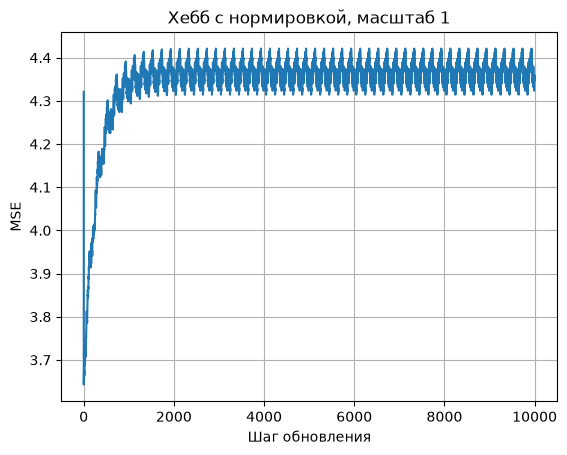

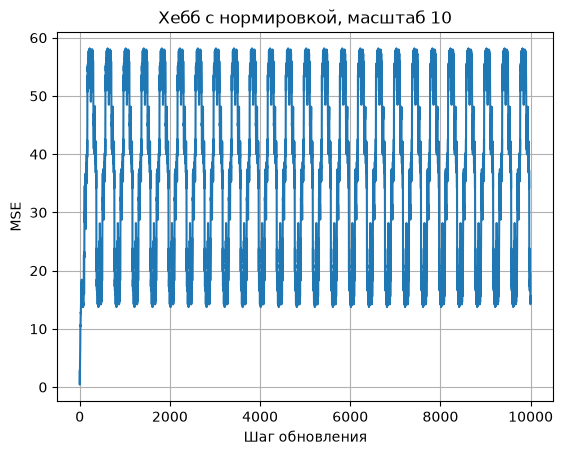

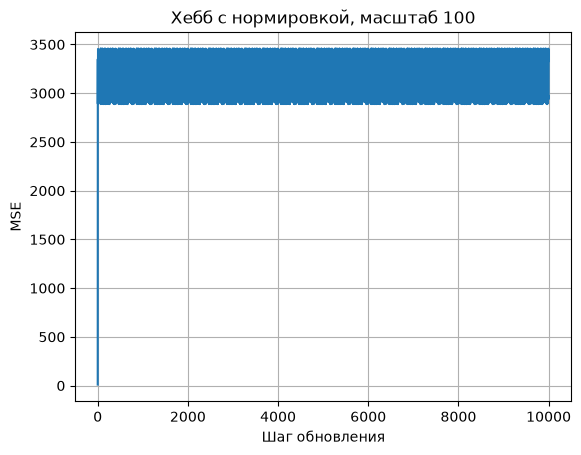

In [23]:
for i in range(3):
    plt.figure()
    plt.plot(loss_norm_scale[i])
    plt.title("Хебб с нормировкой, масштаб " + str(scales[i]))
    plt.xlabel("Шаг обновления")
    plt.ylabel("MSE")
    plt.grid()
    plt.show()

При большом масштабе направление весов меняется от объекта к объекту, поэтому ошибка колеблется так сильно

### Уидро–Хофф

In [24]:
loss_delta_scale = []

for scale in scales:
    X_scale = X * scale
    X_scale_test = X_test * scale
    rng = np.random.default_rng(0)
    w = rng.normal(0, 0.5, 2)
    b = rng.normal(0, 0.5)
    loss = [np.mean((y_scale - (X_scale @ w + b)) ** 2)]

    for i in range(steps):
        j = i % len(X_scale)
        w, b = step_widrow_hoff(X_scale[j], y_scale[j], w, b, mu_scale)
        loss.append(np.mean((y_scale - (X_scale @ w + b)) ** 2))
        if loss[-1] > 1e12:
            break

    loss_delta_scale.append(np.array(loss))
    print("Масштаб", scale, "обновлений", len(loss) - 1)
    print("Последняя MSE на обучении:", loss[-1])
    print("MSE на проверке:", np.mean((y_scale_test - (X_scale_test @ w + b)) ** 2))
    print("Длина весов и смещения:", np.sqrt(w @ w + b ** 2))
    if loss[-1] > 1e12:
        print("Остановка: MSE превысила 1e12")
    print()

Масштаб 1 обновлений 10000
Последняя MSE на обучении: 0.06302365508517965
MSE на проверке: 0.05862649798076994
Длина весов и смещения: 3.801524267994773

Масштаб 10 обновлений 10000
Последняя MSE на обучении: 0.06613341079100418
MSE на проверке: 0.06377274931297838
Длина весов и смещения: 1.0515030356320398

Масштаб 100 обновлений 5
Последняя MSE на обучении: 1450999888281.2654
MSE на проверке: 1764000519253.92
Длина весов и смещения: 20994.39410009754
Остановка: MSE превысила 1e12



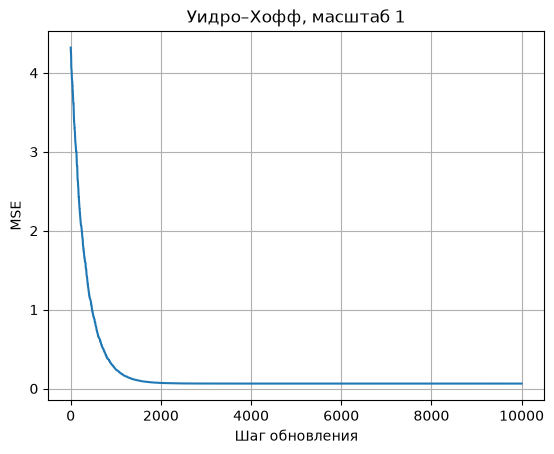

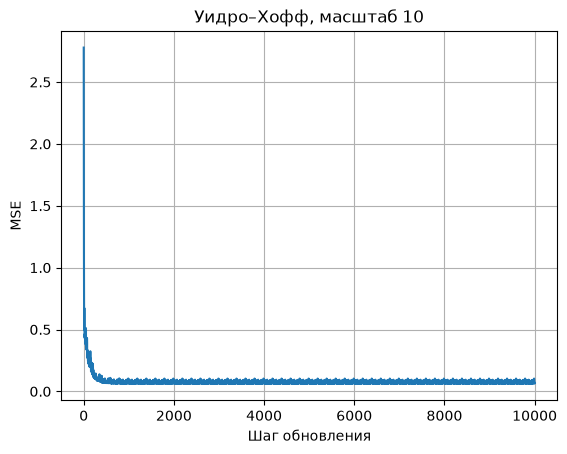

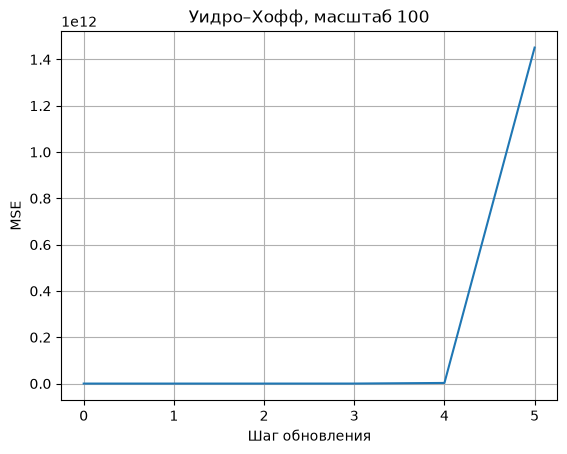

In [25]:
for i in range(3):
    plt.figure()
    plt.plot(loss_delta_scale[i])
    plt.title("Уидро–Хофф, масштаб " + str(scales[i]))
    plt.xlabel("Шаг обновления")
    plt.ylabel("MSE")
    plt.grid()
    plt.show()

При масштабе 1 и 10 обучение устойчиво, при масштабе 100 ошибка превышает порог уже после 4 обновлений => прежний learning rate слишком большой.

## 5. Нелинейная активация сигмоиды

In [26]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def step_sigmoid(x, y, w, b, eta):
    y_pred = sigmoid(w @ x + b)
    error = y - y_pred
    w_new = w + eta * x * error
    b_new = b + eta * error
    return w_new, b_new


def step_sigmoid_grad(x, y, w, b, eta):
    y_pred = sigmoid(w @ x + b)
    error = (y - y_pred) * y_pred * (1 - y_pred)
    w_new = w + eta * x * error
    b_new = b + eta * error
    return w_new, b_new

In [27]:
y_activation = Y[0]
y_activation_test = Y_test[0]
eta_activation = 0.01
epochs_activation = 100

rng = np.random.default_rng(0)
w = rng.normal(0, 0.5, 2)
b = rng.normal(0, 0.5)

train_sigmoid = [np.mean((y_activation - sigmoid(X @ w + b)) ** 2)]
test_sigmoid = [np.mean((y_activation_test - sigmoid(X_test @ w + b)) ** 2)]

for epoch in range(epochs_activation):
    for j in range(len(X)):
        w, b = step_sigmoid(X[j], y_activation[j], w, b, eta_activation)

    train_sigmoid.append(np.mean((y_activation - sigmoid(X @ w + b)) ** 2))
    test_sigmoid.append(np.mean((y_activation_test - sigmoid(X_test @ w + b)) ** 2))

print("MSE без производной:", test_sigmoid[-1])

MSE без производной: 2.6886909276937616


In [28]:
rng = np.random.default_rng(0)
w = rng.normal(0, 0.5, 2)
b = rng.normal(0, 0.5)

train_sigmoid_grad = [np.mean((y_activation - sigmoid(X @ w + b)) ** 2)]
test_sigmoid_grad = [np.mean((y_activation_test - sigmoid(X_test @ w + b)) ** 2)]

for epoch in range(epochs_activation):
    for j in range(len(X)):
        w, b = step_sigmoid_grad(X[j], y_activation[j], w, b, eta_activation)

    train_sigmoid_grad.append(np.mean((y_activation - sigmoid(X @ w + b)) ** 2))
    test_sigmoid_grad.append(np.mean((y_activation_test - sigmoid(X_test @ w + b)) ** 2))

print("MSE с производной:", test_sigmoid_grad[-1])

MSE с производной: 2.697112499898189


### Графики MSE

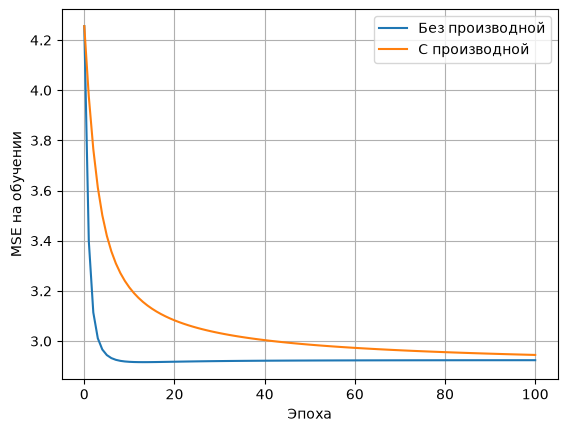

In [29]:
plt.figure()
plt.plot(train_sigmoid, label="Без производной")
plt.plot(train_sigmoid_grad, label="С производной")
plt.xlabel("Эпоха")
plt.ylabel("MSE на обучении")
plt.legend()
plt.grid()
plt.show()

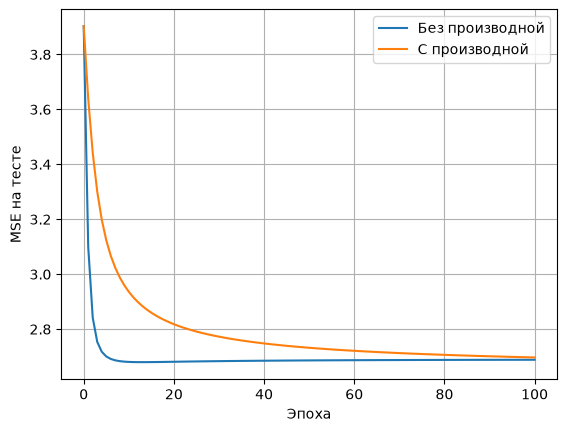

In [30]:
plt.figure()
plt.plot(test_sigmoid, label="Без производной")
plt.plot(test_sigmoid_grad, label="С производной")
plt.xlabel("Эпоха")
plt.ylabel("MSE на тесте")
plt.legend()
plt.grid()
plt.show()

### Объяснение

На графиках оба варианта уменьшают MSE. Без производной ошибка здесь падает быстрее. Но "точное" правило означает совпадение с градиентом MSE, а не более быстрое обучение при одном learning rate.

Ответы взяты из пункта 2. Сигмоида выдает только числа от 0 до 1, поэтому на этой задаче ошибка не может стать нулевой даже с правильной производной.

$z = w^Tx + b$, $\hat y = \sigma(z) = \frac{1}{1 + e^{-z}}$

$L = \frac12(y - \hat y)^2$

По цепному правилу

$\frac{\partial L}{\partial w_i} = \frac{\partial L}{\partial \hat y}\frac{\partial \hat y}{\partial z}\frac{\partial z}{\partial w_i} = (\hat y - y)\hat y(1 - \hat y)x_i$.

Правильное обновление

$w_i^{(n+1)} = w_i^{(n)} + \eta x_i(y - \hat y)\hat y(1 - \hat y)$

$b^{(n+1)} = b^{(n)} + \eta(y - \hat y)\hat y(1 - \hat y)$.

Для MSE без множителя 1/2 постоянный множитель 2 включается в learning rate.

У линейного выхода производная равна 1. У сигмоиды она равна $\hat y(1 - \hat y)$ и зависит от предсказания.

В старом правиле этого множителя нет => после добавления сигмоиды оно больше не является точным шагом против градиента MSE.

## Вывод

1. Реализованы правило Хебба без нормировки, правило Хебба с нормировкой и дельта-правило Уидро–Хоффа для линейного нейрона.

2. На трех уровнях шума и десяти инициализациях Уидро–Хофф дал наименьшую тестовую MSE, нормированный Хебб сохранил большую ошибку, а Хебб без нормировки привел к взрыву весов и ошибки.

3. При нулевом среднем входов усредненное правило Хебба без нормировки обычно расходится, нормированный вариант при условиях пункта 3 выделяет главное направление расширенных входов с учетом смещения, а Уидро–Хофф при подходящем шаге сходится к минимуму MSE.

4. Масштабирование входов в 10 и 100 раз ускорило рост весов обычного Хебба и ухудшило качество нормированного Хебба, а Уидро–Хофф при масштабе 100 потерял устойчивость с прежним learning rate.

5. После добавления сигмоиды старое правило Уидро–Хоффа перестало совпадать с антиградиентом MSE, поскольку по цепному правилу в обновлении должен появиться множитель $\hat y(1 - \hat y)$.

### В каких условиях правило Хебба все еще применимо?

Правило Хебба применимо при обучении без учителя для выделения связей и главных направлений входных данных при условии стабилизации весов, контроля масштаба признаков и выбора подходящего шага.

Для выделения первой главной компоненты в усредненной модели входы центрируют, смещение фиксируют равным нулю и нормируют веса, причем главное направление должно быть единственным, а начальные веса должны иметь ненулевую проекцию на него.

Для последовательного алгоритма с постоянным шагом точная сходимость не гарантируется, а минимизация MSE(или чего-то другого) по правильным ответам не является целью этого правила.

### Почему дельта-правило является частным случаем обратного распространения?

Дельта-правило получается из обратного распространения для одного линейного выходного нейрона с квадратичной ошибкой, поскольку производная линейной активации равна 1 и цепное правило дает

$\frac{\partial L}{\partial w_i} = (\hat y - y)x_i$, где $L = \frac12(y - \hat y)^2$.

Шаг против этого градиента совпадает с правилом Уидро–Хоффа

$w_i^{(n+1)} = w_i^{(n)} + \eta x_i(y - \hat y)$

$b^{(n+1)} = b^{(n)} + \eta(y - \hat y)$.

В многослойной сети то же цепное правило применяется также между слоями.